# Previsão de Vendas - Pré-processamento + Regressão

Objetivo: prever **sales** (unidades vendidas por dia, loja e família de produto).

In [ ]:
import pandas as pd

pasta = 'store-sales-time-series-forecasting/'

# base principal: vendas por dia, loja e família
tabela = pd.read_csv(pasta + 'train.csv', sep=',')

# dados de cada loja (tipo e cluster)
lojas = pd.read_csv(pasta + 'stores.csv', sep=',')

# preço do petróleo por dia
petroleo = pd.read_csv(pasta + 'oil.csv', sep=',')

display(tabela)

## Pré-processamento da base

A base original tem cerca de 3 milhões de registros. Para tornar a análise executável, usamos as lojas 1 a 5 e datas a partir de 2016. Descartamos também o período anterior à primeira venda de cada loja (a loja ainda não existia e o `sales = 0` não é falta de demanda). Nesta etapa também unificamos os dados das lojas e do petróleo, tratamos valores ausentes e duplicados, transformamos atributos e reduzimos a cardinalidade de `onpromotion`.


In [ ]:
# 0) Descartar o periodo anterior a primeira venda de cada loja (a loja ainda nao existia)
# Essas linhas tem sales = 0 nao por falta de demanda, e sim porque a loja nao tinha aberto.
# Feito antes do recorte para usar todo o historico de cada loja.
vendas_dia = tabela.groupby(['store_nbr', 'date'])['sales'].sum().reset_index()
primeira_venda = vendas_dia[vendas_dia['sales'] > 0].groupby('store_nbr')['date'].min()
tabela['primeira_venda'] = tabela['store_nbr'].map(primeira_venda)
antes = len(tabela)
tabela = tabela[tabela['date'] >= tabela['primeira_venda']].drop(columns='primeira_venda')
print('Linhas anteriores a abertura da loja removidas:', antes - len(tabela))

# 1) Reduzir o numero de exemplos para as lojas 1 a 5 e datas a partir de 2016
tabela = tabela[(tabela['store_nbr'] <= 5) & (tabela['date'] >= '2016-01-01')].copy()
print('Registros apos o recorte:', len(tabela))

# 2) Remover apenas linhas inteiramente duplicadas e tratar campos essenciais ausentes
duplicados = tabela.duplicated().sum()
print('Linhas duplicadas:', duplicados)
if duplicados:
    tabela = tabela.drop_duplicates().copy()

chaves_essenciais = ['date', 'store_nbr', 'family', 'sales']
faltantes_chaves = tabela[chaves_essenciais].isna().any(axis=1).sum()
print('Linhas com data, loja, familia ou vendas ausentes:', faltantes_chaves)
if faltantes_chaves:
    tabela = tabela.dropna(subset=chaves_essenciais).copy()

# 3) Unificar dados de loja e petroleo com a tabela de vendas
tabela = tabela.merge(lojas[['store_nbr', 'type', 'cluster']], on='store_nbr', how='left')

petroleo['date'] = pd.to_datetime(petroleo['date'])
dias = pd.date_range(petroleo['date'].min(), '2017-08-31')
petroleo = petroleo.set_index('date').reindex(dias).ffill().bfill().rename_axis('date').reset_index()
tabela['date'] = pd.to_datetime(tabela['date'])
tabela = tabela.merge(petroleo, on='date', how='left')

# 4) Tratar atributos explicativos ausentes: mediana para numericos e categoria explicita para texto
for atributo in tabela.select_dtypes(include='number').columns:
    if atributo != 'sales' and tabela[atributo].isna().any():
        tabela[atributo] = tabela[atributo].fillna(tabela[atributo].median())

for atributo in ['family', 'type']:
    tabela[atributo] = tabela[atributo].fillna('Desconhecido')

# 5) Investigar valores extremos de vendas; não remove-los automaticamente,
# pois picos podem representar demanda real
q1_vendas, q3_vendas = tabela['sales'].quantile([0.25, 0.75])
iqr_vendas = q3_vendas - q1_vendas
limite_inferior = q1_vendas - 1.5 * iqr_vendas
limite_superior = q3_vendas + 1.5 * iqr_vendas
fora_iqr = ~tabela['sales'].between(limite_inferior, limite_superior)
print(f'Vendas fora dos limites IQR [{limite_inferior:.2f}, {limite_superior:.2f}]: {fora_iqr.sum()} (mantidas para analise)')

# 6) Reduzir a cardinalidade de onpromotion para quatro faixas ordenadas
# Faixas: 0, 1-3, 4-16 e acima de 16 itens em promocao.
def agrupar_promocoes(valores):
    return pd.cut(
        valores,
        bins=[-1, 0, 3, 16, float('inf')],
        labels=[0, 1, 2, 3]
    ).astype('int8')

valores_promocao_originais = tabela['onpromotion'].nunique()
tabela['onpromotion'] = agrupar_promocoes(tabela['onpromotion'])
print('Valores distintos de onpromotion:', valores_promocao_originais, '->', tabela['onpromotion'].nunique())

# 7) Transformar a data em atributos numericos
tabela['dia_semana'] = tabela['date'].dt.dayofweek
tabela['dia_mes'] = tabela['date'].dt.day
tabela['mes'] = tabela['date'].dt.month

# 8) Remover id e data original; converter categorias em colunas numericas
tabela = tabela.drop(columns=['id', 'date'])
tabela = pd.get_dummies(tabela, columns=['family', 'type'], dtype=int)

# Preencher eventuais ausencias numericas restantes com a mediana do atributo
for atributo in tabela.columns:
    if atributo != 'sales' and tabela[atributo].isna().any():
        tabela[atributo] = tabela[atributo].fillna(tabela[atributo].median())

print('Atributos disponiveis antes da selecao:', tabela.drop(columns='sales').shape[1])
display(tabela)


## Distribuição e valores extremos das vendas

As vendas têm distribuição assimétrica. O intervalo interquartil serve como diagnóstico; não removemos automaticamente valores extremos, que podem representar picos legítimos de demanda.


,count,mean,std,min,25%,50%,75%,max
sales,97680.0,532.809007,1482.493519,0.0,6.0,37.0,332.87625,124717.0


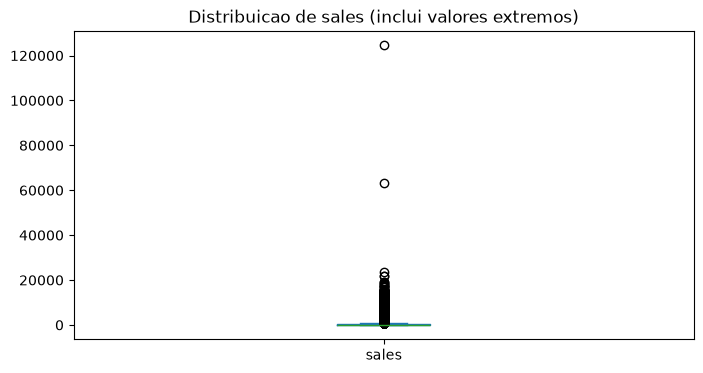

In [17]:
import matplotlib.pyplot as plt

display(tabela['sales'].describe().to_frame().T)
tabela['sales'].plot.box(figsize=(8, 4), title='Distribuicao de sales (inclui valores extremos)')
plt.show()


In [18]:
print(tabela.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 97680 entries, 0 to 97679
Data columns (total 42 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   store_nbr                          97680 non-null  int64  
 1   sales                              97680 non-null  float64
 2   onpromotion                        97680 non-null  int8   
 3   cluster                            97680 non-null  int64  
 4   dcoilwtico                         97680 non-null  float64
 5   dia_semana                         97680 non-null  int32  
 6   dia_mes                            97680 non-null  int32  
 7   mes                                97680 non-null  int32  
 8   family_AUTOMOTIVE                  97680 non-null  int64  
 9   family_BABY CARE                   97680 non-null  int64  
 10  family_BEAUTY                      97680 non-null  int64  
 11  family_BEVERAGES                   97680 non-null  int

,sales
store_nbr,-0.009861
sales,1.000000
onpromotion,0.484336
cluster,-0.020182
dcoilwtico,0.005661
dia_semana,0.029336
dia_mes,-0.009389
mes,0.001034
family_AUTOMOTIVE,-0.062750
family_BABY CARE,-0.063494


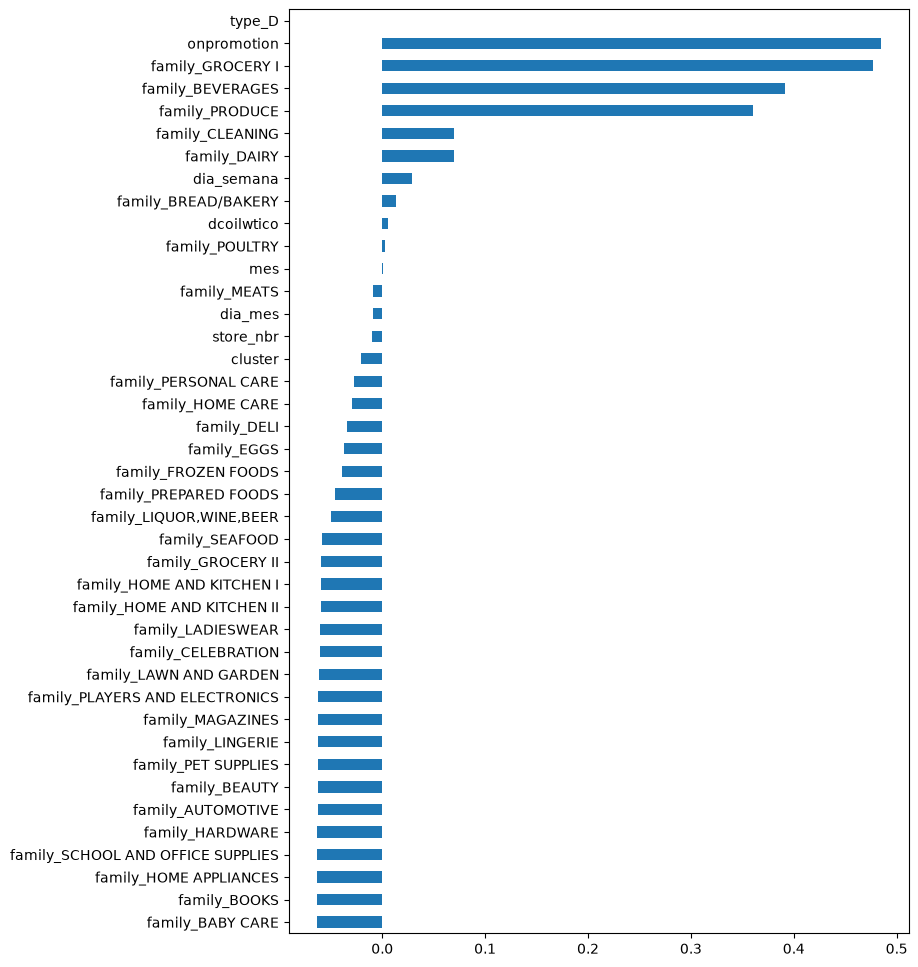

In [19]:
display(tabela.corr()[["sales"]])

# opcional
import matplotlib.pyplot as plt

# gráfico das correlações com sales
tabela.corr()['sales'].drop('sales').sort_values().plot(kind='barh', figsize=(8, 12))
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# y = o que queremos prever (vendas); x = todas as outras colunas
y = tabela["sales"]
x = tabela.drop("sales", axis=1)

# 70% treino, 30% teste
x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.3, random_state=1)

## Redução do número de atributos e normalização

A seleção reduz os atributos de entrada para dez, com SelectKBest ou RFE. Ela é ajustada somente nos dados de treino. O RFE usa padronização para comparar atributos em escalas distintas; a Regressão Linear também será ajustada com atributos padronizados. O Random Forest não precisa de normalização. A seleção reduz colunas, enquanto o agrupamento de `onpromotion` na etapa anterior reduz os valores distintos de um atributo.


In [ ]:
from sklearn.feature_selection import RFE, SelectKBest, f_regression
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

numero_atributos = min(10, x_treino.shape[1])
print('Atributos antes da selecao:', x_treino.shape[1])
print('Atributos selecionados por metodo:', numero_atributos)

# SelectKBest: seleciona os atributos com maior relacao estatistica com sales
seletor_kbest = SelectKBest(score_func=f_regression, k=numero_atributos)
seletor_kbest.fit(x_treino, y_treino)
atributos_kbest = x.columns[seletor_kbest.get_support()].tolist()

# RFE: elimina recursivamente atributos usando regressao linear
seletor_rfe = RFE(
    estimator=make_pipeline(StandardScaler(), LinearRegression()),
    importance_getter='named_steps.linearregression.coef_',
    n_features_to_select=numero_atributos
)
seletor_rfe.fit(x_treino, y_treino)
atributos_rfe = x.columns[seletor_rfe.get_support()].tolist()

print('Atributos selecionados por SelectKBest:', atributos_kbest)
print('Atributos selecionados por RFE:', atributos_rfe)

x_treino_kbest = x_treino[atributos_kbest]
x_teste_kbest = x_teste[atributos_kbest]
x_treino_rfe = x_treino[atributos_rfe]
x_teste_rfe = x_teste[atributos_rfe]


In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Normalizar os atributos apenas dentro da Regressao Linear.
# O Random Forest usa os dados sem escala, pois nao depende de distancias ou magnitudes.
modelos_kbest = {
    'Regressao Linear': make_pipeline(StandardScaler(), LinearRegression()),
    'Random Forest': RandomForestRegressor(n_estimators=50, n_jobs=-1, random_state=1)
}
modelos_rfe = {
    'Regressao Linear': make_pipeline(StandardScaler(), LinearRegression()),
    'Random Forest': RandomForestRegressor(n_estimators=50, n_jobs=-1, random_state=1)
}

for modelo in modelos_kbest.values():
    modelo.fit(x_treino_kbest, y_treino)

for modelo in modelos_rfe.values():
    modelo.fit(x_treino_rfe, y_treino)


In [ ]:
# importar pacotes necessários
import numpy as np
import matplotlib.pyplot as plt

# gráfico: produtos em promoção x vendas
plt.figure(figsize = (16,8))
plt.scatter(
    tabela['onpromotion'],
    tabela['sales'],
    c='red')
plt.xlabel("Produtos em promoção")
plt.ylabel("Vendas")
plt.show()

In [ ]:
from sklearn.metrics import r2_score

# Comparar os dois metodos usando os mesmos dados de teste
previsoes_teste = {
    'SelectKBest - Regressao Linear': modelos_kbest['Regressao Linear'].predict(x_teste_kbest),
    'SelectKBest - Random Forest': modelos_kbest['Random Forest'].predict(x_teste_kbest),
    'RFE - Regressao Linear': modelos_rfe['Regressao Linear'].predict(x_teste_rfe),
    'RFE - Random Forest': modelos_rfe['Random Forest'].predict(x_teste_rfe)
}

for nome, previsao_teste in previsoes_teste.items():
    print(f'{nome}: R2 = {r2_score(y_teste, previsao_teste):.4f}')

In [ ]:
tabela_auxiliar = pd.DataFrame({
    'Vendas reais': y_teste.to_numpy(),
    'Random Forest - SelectKBest': previsoes_teste['SelectKBest - Random Forest'],
    'Random Forest - RFE': previsoes_teste['RFE - Random Forest']
})

# Mostrar apenas as 200 primeiras linhas para facilitar a leitura
tabela_auxiliar.head(200).plot(figsize=(14, 5))
plt.show()


In [ ]:
# Mostrar a equacao da regressao linear com entradas padronizadas
modelo_linear_rfe = modelos_rfe['Regressao Linear']
normalizador_rfe = modelo_linear_rfe.named_steps['standardscaler']
regressao_linear_rfe = modelo_linear_rfe.named_steps['linearregression']

print('Equacao RFE: vendas = intercepto + soma(coeficiente * atributo padronizado)')
print(f'Intercepto: {regressao_linear_rfe.intercept_:.4f}')
for atributo, coeficiente, media, escala in zip(
    atributos_rfe,
    regressao_linear_rfe.coef_,
    normalizador_rfe.mean_,
    normalizador_rfe.scale_
):
    print(f'    + {coeficiente:.4f} * (({atributo} - {media:.4f}) / {escala:.4f})')
